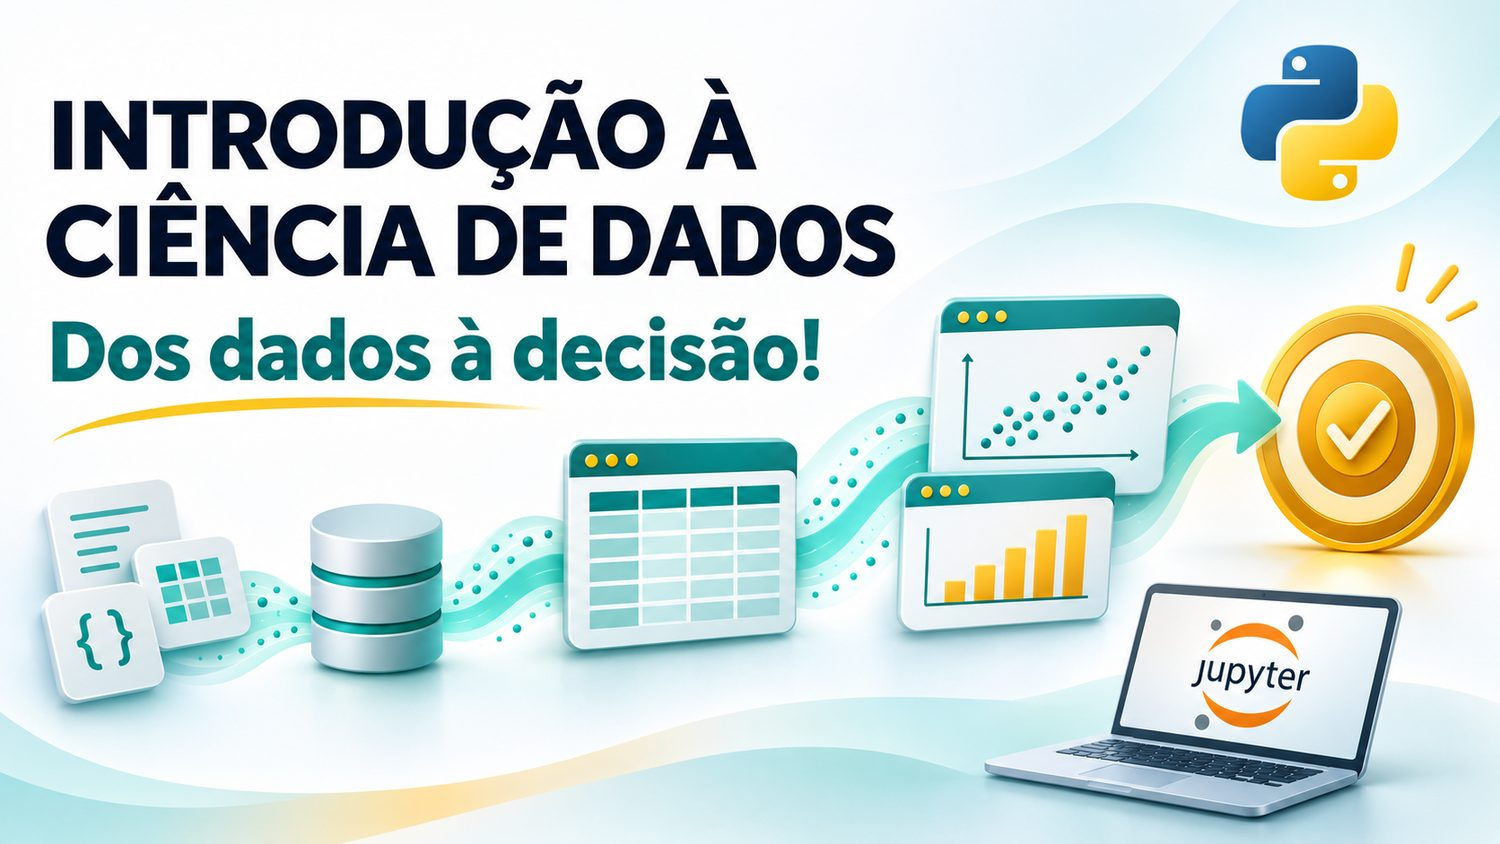

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_6_modelos_supervisionados/01_Metricas_de_Avaliacao.ipynb)

# Capítulo 1 – Métricas de avaliação

Antes de estudar modelos, é preciso saber medi-los. A medida de desempenho é o **P** da definição de Mitchell, e escolhê-la mal leva a escolher mal o modelo. Este capítulo apresenta as métricas mais usadas em classificação e em regressão, o que cada uma premeia e o que cada uma esconde.

> **Objetivos:** ler uma matriz de confusão; calcular e interpretar exatidão, precisão, sensibilidade, especificidade e F1; perceber o compromisso entre precisão e sensibilidade e o papel do limiar; ler uma curva ROC e a sua área; calcular e interpretar MAE, MSE, RMSE, MAPE e R²; analisar resíduos; escolher a métrica a partir da decisão que o modelo apoia.

**Pré-requisitos:** módulo 4, e o capítulo 3 do módulo 1. A sintaxe está em [Scikit-Learn: classificação](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_2_avancado/N2_04_ScikitLearn_Classificacao.ipynb).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

## O caso deste módulo: entregas atrasadas

Uma empresa de distribuição urbana promete a cada cliente uma hora de entrega, calculada pela distância e pelo número de paragens. Uma parte das entregas chega depois do prometido. A empresa quer:

- **prever se uma entrega vai atrasar** (classificação), para avisar o cliente a tempo;
- **prever quanto tempo vai demorar** (regressão), para prometer melhor.

Os dados são sintéticos.

In [2]:
def gerar_entregas(n=4000, semente=29):
    """Gera entregas de uma empresa fictícia de distribuição urbana (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    distancia = rng.gamma(2.2, 2.6, n).clip(0.4, 25).round(1)
    hora = rng.uniform(8, 21, n).round(2)
    paragens = rng.poisson(1.2, n)
    peso = rng.gamma(1.6, 3.0, n).clip(0.1, 30).round(1)
    chuva = rng.random(n) < 0.2
    zona = rng.choice(["centro", "periferia", "rural"], n, p=[0.5, 0.35, 0.15])
    veiculo = np.where(distancia < 3, rng.choice(["bicicleta", "mota"], n, p=[0.6, 0.4]),
                       rng.choice(["mota", "carrinha"], n, p=[0.55, 0.45]))
    hora_de_ponta = ((hora >= 8) & (hora < 9.5)) | ((hora >= 17) & (hora < 19.5))
    transito = np.where(hora_de_ponta, np.where(zona == "centro", 1.75, 1.45), 1.0)
    por_km = np.select([veiculo == "bicicleta", veiculo == "mota"], [4.2, 2.9], 3.3)
    tempo = (7 + distancia * por_km * transito * np.where(chuva, 1.25, 1.0) * np.where(zona == "rural", 0.85, 1.0)
             + 4.0 * paragens + 0.15 * peso + rng.normal(0, 3.5, n))
    tempo = np.where(rng.random(n) < 0.015, tempo + rng.uniform(40, 120, n), tempo)       # avarias e enganos de morada
    prometido = 16 + 3.6 * distancia + 4.0 * paragens
    return pd.DataFrame({"distancia_km": distancia, "hora": hora, "paragens": paragens, "peso_kg": peso,
                         "chuva": chuva, "zona": zona, "veiculo": veiculo,
                         "tempo_min": tempo.clip(4).round(1), "atrasada": tempo > prometido})


entregas = gerar_entregas()
entregas.head()

,distancia_km,hora,paragens,peso_kg,chuva,zona,veiculo,tempo_min,atrasada
0,3.6,9.05,3,2.2,False,periferia,carrinha,35.7,False
1,4.3,16.95,0,12.8,False,centro,mota,25.3,False
2,5.1,14.79,1,3.9,True,periferia,carrinha,34.0,False
3,6.0,8.43,1,9.8,False,periferia,mota,44.0,True
4,7.2,14.07,0,2.4,False,centro,mota,33.5,False


| Coluna | Significado |
| --- | --- |
| `distancia_km` | Distância do armazém ao destino |
| `hora` | Hora de saída (8,5 = 8h30) |
| `paragens` | Outras entregas feitas pelo caminho |
| `peso_kg` | Peso da encomenda |
| `chuva` | Se estava a chover |
| `zona` | Centro, periferia ou rural |
| `veiculo` | Bicicleta, mota ou carrinha |
| `tempo_min` | Tempo que a entrega demorou (alvo de regressão) |
| `atrasada` | Se chegou depois do prometido (alvo de classificação) |

Neste capítulo, os modelos são só um meio para ter previsões que possamos avaliar. Usamos dois, com a preparação do módulo 4, e tratamo-los como caixas fechadas: o **modelo A** (uma regressão logística, do módulo 5) e o **modelo B** (uma árvore de decisão, que estudaremos no capítulo 4).

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

numericas, nominais = ["distancia_km", "hora", "paragens", "peso_kg", "chuva"], ["zona", "veiculo"]
X, y = entregas[numericas + nominais], entregas["atrasada"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)


def preparacao():
    return ColumnTransformer([("num", StandardScaler(), numericas), ("cat", OneHotEncoder(), nominais)])


modelo_a = make_pipeline(preparacao(), LogisticRegression(max_iter=2000)).fit(X_treino, y_treino)
modelo_b = make_pipeline(preparacao(), DecisionTreeClassifier(max_depth=5, random_state=0)).fit(X_treino, y_treino)
previsao_a, previsao_b = modelo_a.predict(X_teste), modelo_b.predict(X_teste)
print(f"Entregas de teste: {len(y_teste)}, das quais {int(y_teste.sum())} atrasadas ({y_teste.mean():.1%})")

Entregas de teste: 1200, das quais 174 atrasadas (14.5%)


## Parte 1 – Classificação

### A matriz de confusão

Todas as métricas de classificação saem de uma tabela com quatro contagens. A classe que nos interessa detetar (aqui, «atrasada») chama-se **positiva**.

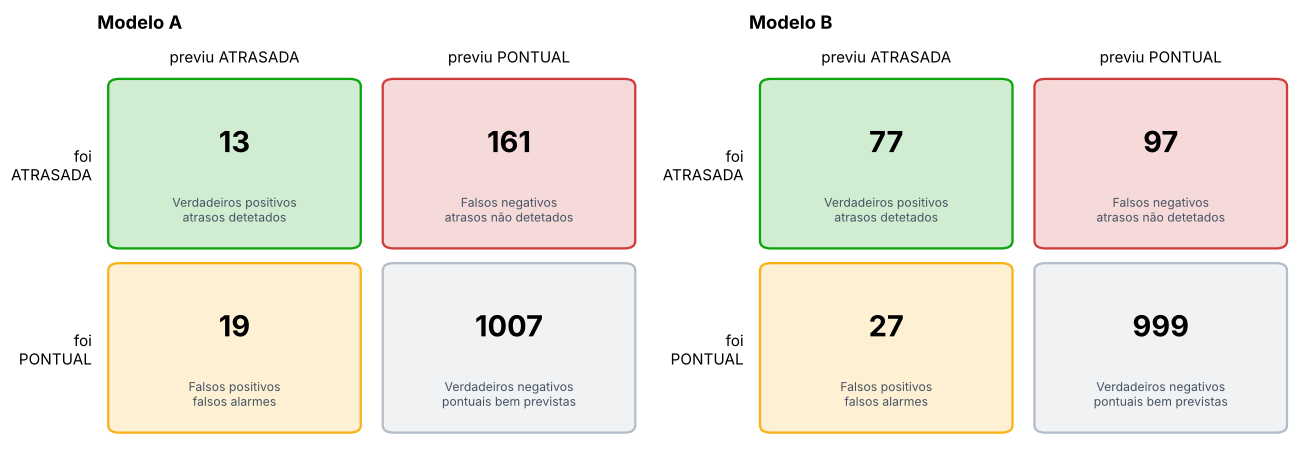

In [4]:
def contagens(real, previsto):
    real, previsto = np.asarray(real), np.asarray(previsto)
    return {"VP": int((previsto & real).sum()), "FN": int((~previsto & real).sum()),
            "FP": int((previsto & ~real).sum()), "VN": int((~previsto & ~real).sum())}


def desenhar_matriz(ax, c, titulo):
    celulas = [(0, 1, c["VP"], "Verdadeiros positivos\natrasos detetados", BOM), (1, 1, c["FN"], "Falsos negativos\natrasos não detetados", MAU),
               (0, 0, c["FP"], "Falsos positivos\nfalsos alarmes", AVISO), (1, 0, c["VN"], "Verdadeiros negativos\npontuais bem previstas", CINZA)]
    for coluna, linha, valor, rotulo, cor in celulas:
        ax.add_patch(FancyBboxPatch((coluna + 0.04, linha + 0.04), 0.92, 0.92, boxstyle="round,pad=0,rounding_size=0.04", fc=cor + "30", ec=cor, lw=1.5))
        ax.text(coluna + 0.5, linha + 0.62, str(valor), ha="center", va="center", fontsize=19, fontweight="bold")
        ax.text(coluna + 0.5, linha + 0.25, rotulo, ha="center", va="center", fontsize=8, color="#465463")
    ax.set_xlim(0, 2)
    ax.set_ylim(0, 2)
    ax.set_xticks([0.5, 1.5], ["previu ATRASADA", "previu PONTUAL"])
    ax.set_yticks([0.5, 1.5], ["foi\nPONTUAL", "foi\nATRASADA"])
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    ax.spines[:].set_visible(False)
    ax.set_title(titulo, pad=28)


c_a, c_b = contagens(y_teste, previsao_a), contagens(y_teste, previsao_b)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
desenhar_matriz(ax1, c_a, "Modelo A")
desenhar_matriz(ax2, c_b, "Modelo B")
plt.tight_layout()
plt.show()

Lê primeiro as **linhas**: a de cima são as entregas que de facto atrasaram, a de baixo as pontuais. Depois as **colunas**: o que o modelo disse. A diagonal (verde e cinzento) são os acertos; as outras duas células são os dois tipos de erro.

### Exatidão, e porque não chega

A **exatidão** (*accuracy*) é a fração de previsões certas: (VP + VN) ÷ total.

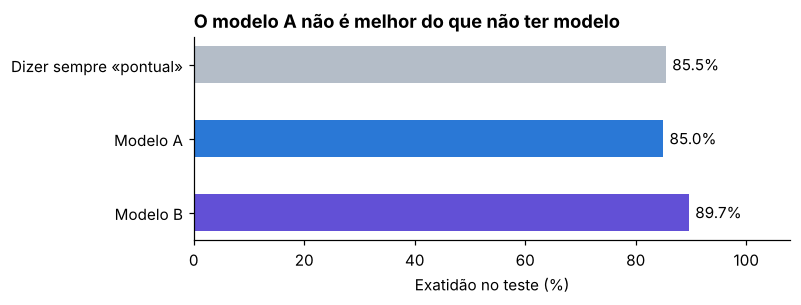

In [5]:
def exatidao(c):
    return (c["VP"] + c["VN"]) / sum(c.values())


sempre_pontual = contagens(y_teste, np.zeros(len(y_teste), dtype=bool))
resultados = {"Dizer sempre «pontual»": exatidao(sempre_pontual), "Modelo A": exatidao(c_a), "Modelo B": exatidao(c_b)}

fig, ax = plt.subplots(figsize=(7, 2.4))
barras = ax.barh(list(resultados), [v * 100 for v in resultados.values()], color=[CINZA, AZUL, VIOLETA], height=0.5)
ax.bar_label(barras, fmt="%.1f%%", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 108)
ax.set_xlabel("Exatidão no teste (%)")
ax.set_title("O modelo A não é melhor do que não ter modelo")
plt.show()

Como só cerca de 14% das entregas atrasam, quem disser sempre «pontual» acerta em 86% dos casos. O modelo A tem praticamente a mesma exatidão, e a matriz mostra porquê: deteta muito poucos atrasos. Já tínhamos visto este efeito no módulo 1: **quando a classe que interessa é rara, a exatidão mede sobretudo a classe que não interessa.**

### Precisão e sensibilidade

Duas perguntas mais úteis, cada uma olhando para uma parte da matriz.

| Métrica | Pergunta | Fórmula | Olha para |
| --- | --- | --- | --- |
| **Sensibilidade** (*recall*) | Dos atrasos que houve, quantos detetei? | VP ÷ (VP + FN) | a linha dos atrasos reais |
| **Precisão** (*precision*) | Dos avisos que dei, quantos se confirmaram? | VP ÷ (VP + FP) | a coluna dos avisos |
| **Especificidade** | Das entregas pontuais, quantas deixei em paz? | VN ÷ (VN + FP) | a linha das pontuais |

In [6]:
def metricas(c):
    sensibilidade = c["VP"] / (c["VP"] + c["FN"])
    precisao = c["VP"] / (c["VP"] + c["FP"]) if c["VP"] + c["FP"] else np.nan
    return {"exatidão": exatidao(c), "sensibilidade": sensibilidade, "precisão": precisao,
            "especificidade": c["VN"] / (c["VN"] + c["FP"]),
            "F1": 2 * precisao * sensibilidade / (precisao + sensibilidade) if c["VP"] else 0.0}


tabela = pd.DataFrame({"Sempre «pontual»": metricas(sempre_pontual), "Modelo A": metricas(c_a), "Modelo B": metricas(c_b)}).T
(tabela * 100).round(1)

,exatidão,sensibilidade,precisão,especificidade,F1
Sempre «pontual»,85.5,0.0,NaN,100.0,0.0
Modelo A,85.0,7.5,40.6,98.1,12.6
Modelo B,89.7,44.3,74.0,97.4,55.4


A tabela conta uma história que a exatidão escondia. O modelo A deteta uma fração pequena dos atrasos; o modelo B deteta pouco menos de metade, e quando avisa acerta cerca de três vezes em cada quatro.

As duas métricas puxam em sentidos opostos:

- para ter **sensibilidade** de 100%, basta avisar toda a gente (e a precisão cai para 14%);
- para ter **precisão** alta, basta avisar só nos casos óbvios (e a sensibilidade cai).

Qual interessa mais depende do custo de cada erro. Um aviso falso incomoda um cliente sem necessidade. Um atraso sem aviso gera uma reclamação. É a pergunta do módulo 1, capítulo 3.

### F1: uma só nota para as duas

O **F1** junta a precisão e a sensibilidade numa única medida. É a sua **média harmónica**: 2 × P × S ÷ (P + S).

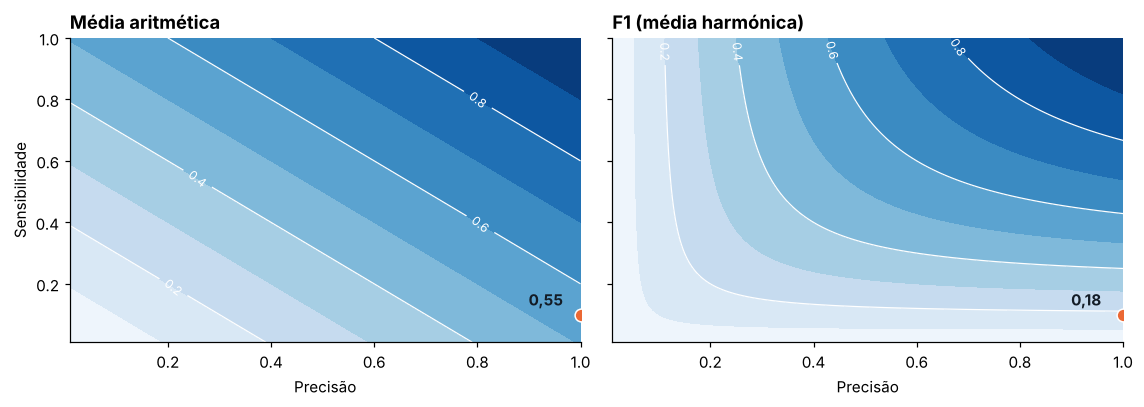

In [7]:
precisoes, sensibilidades = np.meshgrid(np.linspace(0.01, 1, 200), np.linspace(0.01, 1, 200))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.8), sharey=True)
for ax, valores, nota, titulo in [(ax1, (precisoes + sensibilidades) / 2, (1.0 + 0.1) / 2, "Média aritmética"),
                                  (ax2, 2 * precisoes * sensibilidades / (precisoes + sensibilidades), 2 * 1.0 * 0.1 / 1.1, "F1 (média harmónica)")]:
    niveis = ax.contourf(precisoes, sensibilidades, valores, levels=np.linspace(0, 1, 11), cmap="Blues")
    linhas = ax.contour(precisoes, sensibilidades, valores, levels=[0.2, 0.4, 0.6, 0.8], colors="white", linewidths=0.8)
    ax.clabel(linhas, fmt="%.1f", fontsize=8)
    ax.scatter([1.0], [0.1], color=LARANJA, s=70, zorder=3, edgecolor="white")
    ax.annotate(f"{nota:.2f}".replace(".", ","), (1.0, 0.1), textcoords="offset points", xytext=(-34, 6), color=TINTA, fontweight="bold")
    ax.set_title(titulo)
    ax.set_xlabel("Precisão")
ax1.set_ylabel("Sensibilidade")
plt.tight_layout()
plt.show()

O ponto laranja é um modelo com precisão 1,0 e sensibilidade 0,1: nunca se engana quando avisa, mas quase nunca avisa. A média aritmética dá-lhe 0,55, uma nota razoável. O F1 dá-lhe 0,18.

A média harmónica é puxada para o **menor** dos dois valores. Para ter um F1 alto, é preciso ter as duas coisas ao mesmo tempo. É a métrica habitual quando a classe positiva é rara e os dois erros importam mais ou menos o mesmo.

O F1 ignora os verdadeiros negativos e trata a precisão e a sensibilidade como igualmente importantes. Quando um dos erros custa muito mais do que o outro, é melhor olhar para as duas métricas em separado, ou para o custo.

### O limiar muda tudo

Os dois modelos não devolvem «atrasada» ou «pontual»: devolvem uma **probabilidade**. A previsão resulta de comparar essa probabilidade com um **limiar**, que por omissão é 0,5. Mudar o limiar muda a matriz de confusão inteira, sem treinar nada.

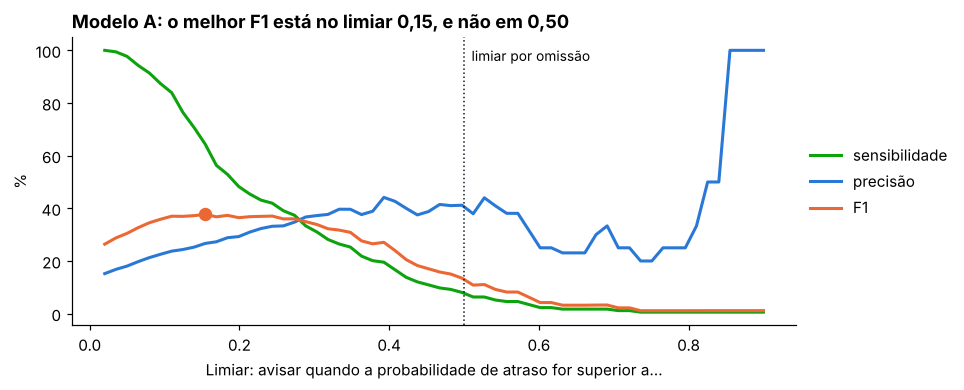

In [8]:
probabilidade_a = modelo_a.predict_proba(X_teste)[:, 1]
probabilidade_b = modelo_b.predict_proba(X_teste)[:, 1]
limiares = np.linspace(0.02, 0.9, 60)


def percorrer(probabilidade):
    return pd.DataFrame([{"limiar": t, **metricas(contagens(y_teste, probabilidade >= t))} for t in limiares])


curva_a = percorrer(probabilidade_a)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
for coluna, cor in [("sensibilidade", BOM), ("precisão", AZUL), ("F1", LARANJA)]:
    ax.plot(curva_a["limiar"], curva_a[coluna] * 100, color=cor, lw=2, label=coluna)
ax.axvline(0.5, color=TINTA, ls=":", lw=1)
ax.text(0.51, 96, "limiar por omissão", fontsize=9)
melhor = curva_a.loc[curva_a["F1"].idxmax()]
ax.scatter([melhor["limiar"]], [melhor["F1"] * 100], color=LARANJA, s=60, zorder=3)
ax.set_xlabel("Limiar: avisar quando a probabilidade de atraso for superior a…")
ax.set_ylabel("%")
ax.set_title(f"Modelo A: o melhor F1 está no limiar {melhor['limiar']:.2f}, e não em 0,50".replace("0.", "0,"))
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5))
plt.show()

Com o limiar por omissão, o modelo A quase nunca avisa. Baixando-o, a sensibilidade sobe e a precisão desce. O modelo A não era tão inútil como a matriz inicial sugeria: estava a ser usado com um limiar inadequado para uma classe rara.

Daqui saem duas regras:

- **o limiar é uma decisão**, que se toma com os custos dos erros na mão, e escolhe-se na validação, nunca no teste;
- para comparar dois modelos de forma justa, convém compará-los **em todos os limiares**, e não só em 0,5.

### Curvas para comparar em todos os limiares

A curva **precisão–sensibilidade** e a curva **ROC** desenham o desempenho de um modelo ao longo de todos os limiares.

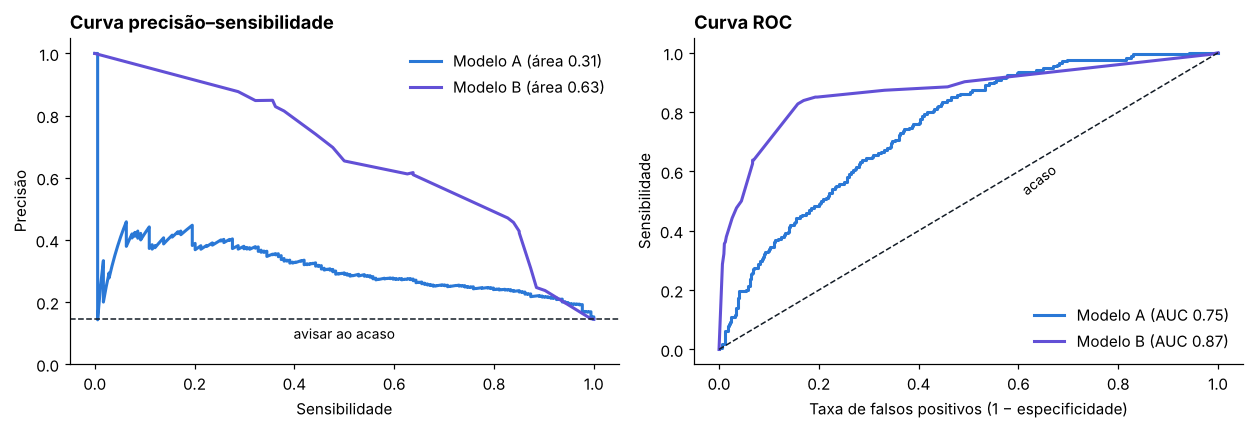

In [9]:
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score, roc_curve

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4))
for nome, prob, cor in [("Modelo A", probabilidade_a, AZUL), ("Modelo B", probabilidade_b, VIOLETA)]:
    p, s, _ = precision_recall_curve(y_teste, prob)
    ax1.plot(s, p, color=cor, lw=2, label=f"{nome} (área {average_precision_score(y_teste, prob):.2f})")
    falsos, verdadeiros, _ = roc_curve(y_teste, prob)
    ax2.plot(falsos, verdadeiros, color=cor, lw=2, label=f"{nome} (AUC {roc_auc_score(y_teste, prob):.2f})")
ax1.axhline(y_teste.mean(), color=TINTA, ls="--", lw=1)
ax1.text(0.5, y_teste.mean() - 0.02, "avisar ao acaso", ha="center", va="top", fontsize=9)
ax1.set_ylim(0, 1.05)
ax1.set_xlabel("Sensibilidade")
ax1.set_ylabel("Precisão")
ax1.set_title("Curva precisão–sensibilidade")
ax1.legend(frameon=False)
ax2.plot([0, 1], [0, 1], color=TINTA, ls="--", lw=1)
ax2.text(0.6, 0.52, "acaso", fontsize=9, rotation=38)
ax2.set_xlabel("Taxa de falsos positivos (1 − especificidade)")
ax2.set_ylabel("Sensibilidade")
ax2.set_title("Curva ROC")
ax2.legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

Em ambas, uma curva mais «encostada ao canto bom» é melhor: o canto superior direito na primeira, o superior esquerdo na segunda.

A **AUC** (área debaixo da curva ROC) resume a curva num número entre 0,5 (acaso) e 1 (perfeito). Tem uma leitura direta: é a probabilidade de o modelo dar uma pontuação mais alta a uma entrega atrasada, escolhida ao acaso, do que a uma pontual. Mede a capacidade de **ordenar**, independentemente do limiar.

Com classes desequilibradas, a curva precisão–sensibilidade é mais informativa. A curva ROC usa a taxa de falsos positivos, calculada sobre as muitas entregas pontuais, e por isso parece boa mesmo quando a maior parte dos avisos é falsa.

### Qual escolher?

| Situação | Métrica principal |
| --- | --- |
| Classes equilibradas e erros com custo parecido | Exatidão |
| Classe positiva rara; os dois erros importam | F1, e a curva precisão–sensibilidade |
| Não detetar custa muito (doença, fraude, avaria) | Sensibilidade, com um mínimo de precisão |
| Um falso alarme custa muito (bloquear um cliente, operar um doente) | Precisão, com um mínimo de sensibilidade |
| Só interessa ordenar (a quem telefonar primeiro) | AUC |
| Os custos são conhecidos | O custo total (módulo 1, capítulo 3) |

Quando há mais de duas classes, calcula-se cada métrica classe a classe e faz-se a média. A média **macro** dá o mesmo peso a todas as classes; a **ponderada** dá mais peso às mais frequentes. Com classes raras, as duas podem ser muito diferentes.

## Parte 2 – Regressão

Em regressão não há «certo» e «errado»: há **quanto** se errou. A unidade de base é o **resíduo**: o valor real menos o previsto.

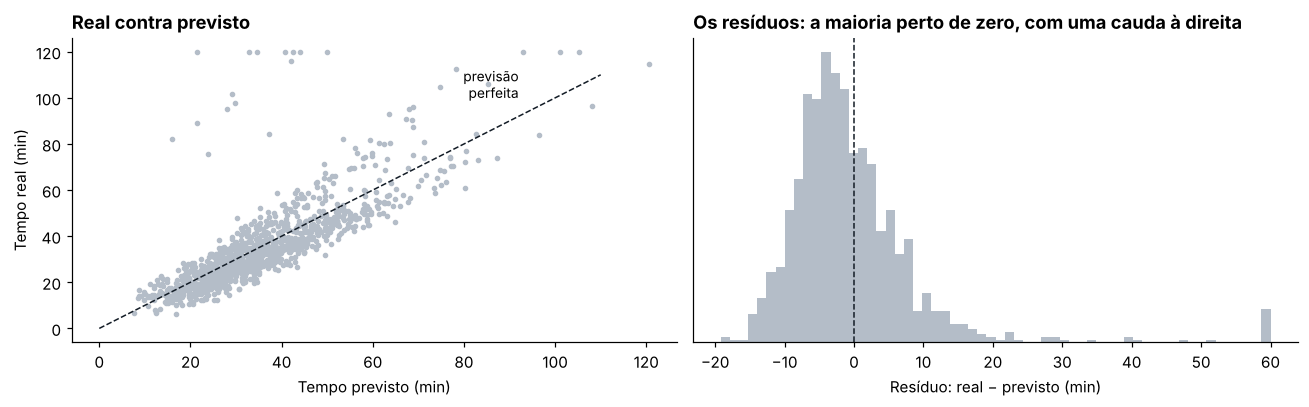

In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

tempo = entregas["tempo_min"]
Xr_treino, Xr_teste, t_treino, t_teste = train_test_split(X, tempo, test_size=0.3, random_state=0)
regressor = make_pipeline(preparacao(), LinearRegression()).fit(Xr_treino, t_treino)
previsto = regressor.predict(Xr_teste)
residuos = t_teste - previsto

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
ax1.scatter(previsto, t_teste.clip(upper=120), s=7, color=CINZA)
ax1.plot([0, 110], [0, 110], color=TINTA, lw=1, ls="--")
ax1.text(92, 100, "previsão\nperfeita", fontsize=9, ha="right")
ax1.set_xlabel("Tempo previsto (min)")
ax1.set_ylabel("Tempo real (min)")
ax1.set_title("Real contra previsto")
ax2.hist(residuos.clip(-30, 60), bins=60, color=CINZA)
ax2.axvline(0, color=TINTA, lw=1, ls="--")
ax2.set_xlabel("Resíduo: real − previsto (min)")
ax2.set_yticks([])
ax2.set_title("Os resíduos: a maioria perto de zero, com uma cauda à direita")
plt.tight_layout()
plt.show()

À esquerda, cada ponto é uma entrega; os que estão em cima da linha tracejada foram previstos na perfeição. À direita, a distribuição dos resíduos. A cauda à direita são entregas que demoraram muito mais do que o previsto: avarias e enganos de morada, que nenhum atributo anuncia.

### As métricas

| Métrica | Cálculo | Unidade | O que premeia |
| --- | --- | --- | --- |
| **MAE** – erro absoluto médio | média de \|resíduo\| | a do alvo | Errar pouco em geral; todos os erros pesam na proporção do seu tamanho |
| **MSE** – erro quadrático médio | média de resíduo² | o quadrado da do alvo | Evitar erros grandes; um erro duplo pesa o quádruplo |
| **RMSE** – raiz do erro quadrático médio | √MSE | a do alvo | O mesmo que o MSE, numa unidade legível |
| **MAPE** – erro percentual absoluto médio | média de \|resíduo\| ÷ real | % | Errar pouco em proporção |
| **R²** – coeficiente de determinação | 1 − MSE do modelo ÷ MSE de prever a média | sem unidade | Explicar a variação do alvo |

In [11]:
def metricas_regressao(real, previsao):
    r = np.asarray(real) - np.asarray(previsao)
    mse = np.mean(r ** 2)
    return {"MAE": np.mean(np.abs(r)), "MSE": mse, "RMSE": np.sqrt(mse),
            "MAPE (%)": np.mean(np.abs(r) / np.asarray(real)) * 100,
            "R²": 1 - mse / np.mean((np.asarray(real) - np.mean(real)) ** 2)}


base = np.full(len(t_teste), t_treino.median())
pd.DataFrame({"Linha de base (mediana)": metricas_regressao(t_teste, base),
              "Regressão linear": metricas_regressao(t_teste, previsto)}).round(2)

,Linha de base (mediana),Regressão linear
MAE,12.49,6.62
MSE,363.70,138.50
RMSE,19.07,11.77
MAPE (%),38.42,19.25
R²,-0.05,0.60


- O **MAE** lê-se diretamente: o modelo erra, em média, pouco menos de 7 minutos.
- O **RMSE** é sempre igual ou superior ao MAE, e a distância entre os dois diz se há erros muito grandes: aqui há.
- O **MAPE** diz que o erro típico é uma certa percentagem do tempo real. Cuidado: quando o valor real é pequeno, uma diferença de poucos minutos dá uma percentagem enorme, e o MAPE não se pode calcular se houver valores reais iguais a zero.
- O **R²** compara o modelo com a previsão mais simples (a média). Vale 1 para um modelo perfeito, 0 para um que não faz melhor do que a média, e pode ser **negativo** para um que faz pior. A linha de base da tabela usa a mediana e por isso fica ligeiramente abaixo de zero.

### MAE ou RMSE? Depende de quanto custa um erro grande

As duas métricas reagem de forma muito diferente a erros raros e grandes. Vamos retirar do teste as 1,5% de entregas com incidentes e ver o que muda.

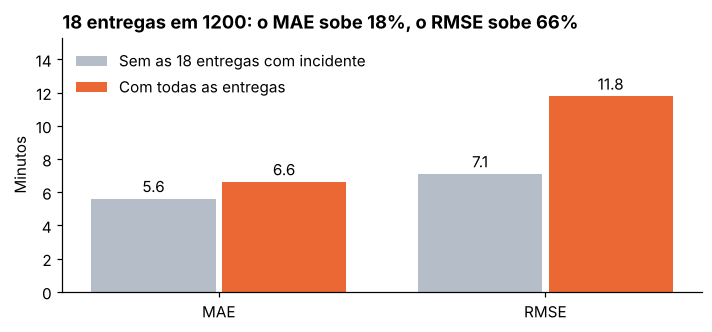

In [12]:
normal = residuos.abs() < 35                                     # entregas sem incidente
com = metricas_regressao(t_teste, previsto)
sem = metricas_regressao(t_teste[normal], previsto[normal])

fig, ax = plt.subplots(figsize=(7.5, 3))
x = np.arange(2)
b1 = ax.bar(x - 0.2, [sem["MAE"], sem["RMSE"]], 0.38, color=CINZA, label=f"Sem as {int((~normal).sum())} entregas com incidente")
b2 = ax.bar(x + 0.2, [com["MAE"], com["RMSE"]], 0.38, color=LARANJA, label="Com todas as entregas")
ax.bar_label(b1, fmt="%.1f", padding=2)
ax.bar_label(b2, fmt="%.1f", padding=2)
ax.set_xticks(x, ["MAE", "RMSE"])
ax.set_ylabel("Minutos")
ax.set_ylim(0, com["RMSE"] * 1.3)
ax.set_title(f"{int((~normal).sum())} entregas em {len(normal)}: o MAE sobe {com['MAE'] / sem['MAE'] - 1:.0%}, o RMSE sobe {com['RMSE'] / sem['RMSE'] - 1:.0%}")
ax.legend(frameon=False, loc="upper left")
plt.show()

Uma pequena fração de entregas com erros enormes mexe pouco no MAE e muito no RMSE, porque os erros entram ao quadrado.

Nenhuma das duas está «certa»:

- se um atraso de uma hora é **muito pior** do que seis atrasos de dez minutos (um cliente perdido contra seis clientes ligeiramente incomodados), o RMSE é a métrica que reflete o negócio;
- se os erros custam **na proporção** do seu tamanho, ou se os valores extremos são incidentes que o modelo não tem como prever, o MAE descreve melhor o desempenho típico.

Há uma ligação com o módulo 3: o MAE está para a **mediana** como o MSE está para a **média**. Um modelo que minimiza o MAE procura o valor típico; um que minimiza o MSE é arrastado pelos casos extremos.

### Os resíduos mostram onde o modelo falha

Uma métrica é um resumo, e um resumo esconde (módulo 3, capítulo 3). Desenhar os resíduos contra um atributo mostra **onde** estão os erros.

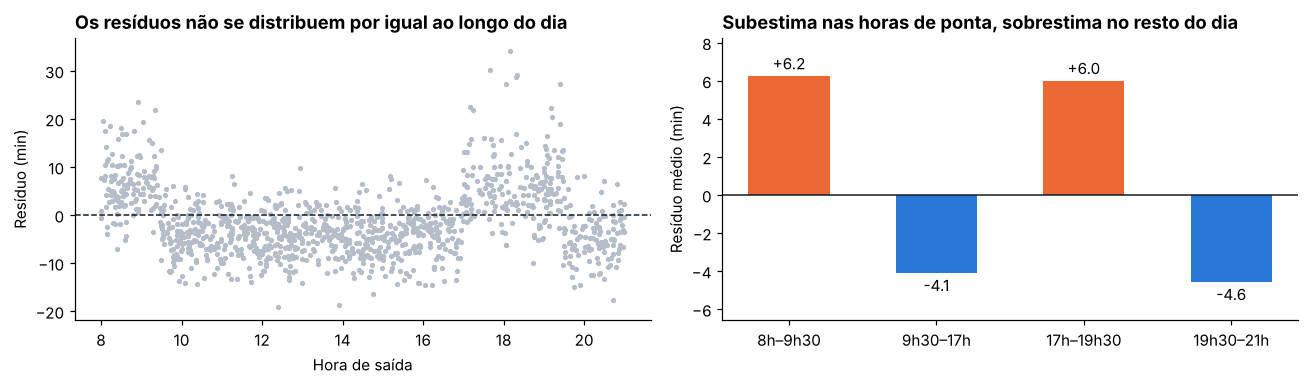

In [13]:
teste = Xr_teste.assign(residuo=residuos)[normal]
teste["periodo"] = pd.cut(teste["hora"], [8, 9.5, 17, 19.5, 21], labels=["8h–9h30", "9h30–17h", "17h–19h30", "19h30–21h"], include_lowest=True)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
ax1.scatter(teste["hora"], teste["residuo"], s=6, color=CINZA)
ax1.axhline(0, color=TINTA, lw=1, ls="--")
ax1.set_xlabel("Hora de saída")
ax1.set_ylabel("Resíduo (min)")
ax1.set_title("Os resíduos não se distribuem por igual ao longo do dia")
media = teste.groupby("periodo", observed=True)["residuo"].mean()
barras = ax2.bar(media.index.astype(str), media, color=[LARANJA if v > 0 else AZUL for v in media], width=0.55)
ax2.bar_label(barras, fmt="%+.1f", padding=2)
ax2.axhline(0, color=TINTA, lw=1)
ax2.set_ylim(media.min() - 2, media.max() + 2)
ax2.set_ylabel("Resíduo médio (min)")
ax2.set_title("Subestima nas horas de ponta, sobrestima no resto do dia")
plt.tight_layout()
plt.show()

Um bom modelo tem resíduos sem padrão: uma nuvem à volta de zero, igual em toda a parte. Aqui há um padrão claro. Nas horas de ponta o modelo prevê tempos demasiado curtos (resíduos positivos), e no resto do dia demasiado longos.

A regressão linear só sabe dizer «cada hora mais tarde acrescenta x minutos». Não consegue representar «demora mais entre as 8h e as 9h30 e entre as 17h e as 19h30». O erro médio esconde este defeito, e é este defeito que os modelos dos próximos capítulos conseguem corrigir.

> **Uma métrica diz quanto o modelo erra. Os resíduos dizem onde e porquê.**

## Três regras para qualquer métrica

1. **Sempre ao lado da linha de base.** Um MAE de 7 minutos não diz nada sem saber que a mediana erra 12.
2. **Sempre no teste** (ou na validação, para escolher). Qualquer métrica calculada no treino é otimista.
3. **Mais do que uma.** Cada métrica vê uma parte do problema. Apresenta a que corresponde à decisão, e as outras como contexto.

## Exercícios

### `Exercício 1` – Contas com a matriz

Um modelo de deteção de fraude analisou 10 000 transações, 100 das quais fraudulentas. Assinalou 300 transações, e 80 eram mesmo fraudes. Calcula VP, FN, FP, VN, a exatidão, a precisão, a sensibilidade e o F1. O modelo é bom?

<details>
<summary><b>Ver uma solução possível</b></summary>

VP = 80; FN = 20; FP = 220; VN = 9 680.

- Exatidão = 9 760 ÷ 10 000 = 97,6% (dizer sempre «legítima» daria 99%).
- Precisão = 80 ÷ 300 = 26,7%.
- Sensibilidade = 80 ÷ 100 = 80%.
- F1 = 2 × 0,267 × 0,8 ÷ 1,067 = 0,40.

Depende do uso. Deteta quatro fraudes em cada cinco, o que é bom, e três em cada quatro alertas são falsos. Se cada alerta levar a uma verificação barata, é um bom modelo. Se levar a bloquear o cartão do cliente, não é.

</details>

### `Exercício 2` – Escolher o limiar pelo custo

Suponhamos que um aviso falso custa 0,50 € (uma mensagem e algum incómodo) e um atraso sem aviso custa 6 € (uma reclamação). Calcula o custo total de cada limiar para o modelo B e indica o melhor. É superior ou inferior a 0,5?

In [14]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
custos = []
for t in limiares:
    c = contagens(y_teste, probabilidade_b >= t)
    custos.append(0.5 * c["FP"] + 6 * c["FN"])
print(f"Melhor limiar: {limiares[int(np.argmin(custos))]:.2f} | custo: {min(custos):.0f} € | com 0,5: {custos[int(np.abs(limiares - 0.5).argmin())]:.0f} €")
```

O melhor limiar fica muito abaixo de 0,5. Como um atraso sem aviso custa doze vezes mais do que um aviso falso, compensa avisar mesmo quando a probabilidade de atraso é baixa. (Num projeto, esta escolha far-se-ia na validação.)

</details>

### `Exercício 3` – Uma métrica com as tuas mãos

Sem usar o scikit-learn, calcula o MAE, o RMSE e o R² destas previsões. Depois troca o último valor real por 90 e repete. Que métrica mudou mais?

In [15]:
real = np.array([22.0, 35.0, 18.0, 41.0, 30.0])
previsao = np.array([25.0, 31.0, 20.0, 38.0, 33.0])
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
for ultimo in [30.0, 90.0]:
    r = np.append(real[:-1], ultimo)
    print(ultimo, {k: round(float(v), 2) for k, v in metricas_regressao(r, previsao).items() if k in ("MAE", "RMSE", "R²")})
```

Com os valores originais, o MAE é 3,0 e o RMSE 3,07: quase iguais, porque os erros são todos do mesmo tamanho. Com um único erro de 57 minutos, o MAE passa para 13,8 e o RMSE para 25,6. O R² cai de 0,87 para perto de zero: bastou um ponto para o modelo parecer tão bom como prever a média. Em amostras pequenas, qualquer métrica depende muito de poucos casos.

</details>

### `Exercício 4` – Resíduos por zona

Calcula o resíduo médio da regressão linear por zona e por veículo. Há algum grupo em que o modelo erre sistematicamente para o mesmo lado? O que sugere isso?

In [16]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
t = Xr_teste.assign(residuo=residuos)[normal]
print(t.groupby("zona")["residuo"].agg(["mean", "count"]).round(2))
print(t.groupby(["veiculo", pd.cut(t["distancia_km"], [0, 3, 8, 25])], observed=True)["residuo"].mean().round(2))
```

Por zona e por veículo, os resíduos médios são pequenos e parecidos: o modelo tem um coeficiente para cada categoria e acerta o nível de cada uma. (São ligeiramente negativos porque retirámos as entregas com incidente, que o modelo tinha «espalhado» por todas as previsões.)

As diferenças maiores aparecem quando se cruza o veículo com a distância: por exemplo, nas entregas longas de mota o modelo prevê tempos demasiado altos. O modelo **soma** o efeito do veículo e o efeito da distância, mas na realidade eles **multiplicam-se**: cada veículo tem o seu tempo por quilómetro. A um efeito que depende de outro atributo chama-se **interação**, e um modelo linear não a vê se não lha dermos.

</details>

## Verifica o que aprendeste

- [ ] Sei ler as quatro células de uma matriz de confusão.
- [ ] Sei calcular a exatidão, a precisão, a sensibilidade, a especificidade e o F1.
- [ ] Sei porque a exatidão engana com classes desequilibradas.
- [ ] Sei explicar o compromisso entre precisão e sensibilidade e o papel do limiar.
- [ ] Sei o que mede a AUC.
- [ ] Sei calcular e interpretar o MAE, o MSE, o RMSE, o MAPE e o R².
- [ ] Sei quando o RMSE e o MAE levam a conclusões diferentes.
- [ ] Sei usar os resíduos para ver onde um modelo falha.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/model_evaluation.html
- https://en.wikipedia.org/wiki/Confusion_matrix
- https://en.wikipedia.org/wiki/Precision_and_recall
- https://en.wikipedia.org/wiki/Receiver_operating_characteristic
- https://en.wikipedia.org/wiki/Coefficient_of_determination